<a href="https://colab.research.google.com/github/Durga2924/FLA-TASK-3-CLA-2/blob/main/TASK_3_FLA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TASK 3: CASE STUDIES WITH PDA AND CFG
PUSHDOWN AUTOMATA AND CONTEXT-FREE GRAMMAR

CASE STUDY 1: BALANCED PARENTHESES

Problem:
Design a PDA to check whether parentheses, square brackets,
and curly brackets are balanced and properly nested.

CFG:

S -> B S | B
B -> ( S ) | () | [ S ] | [] | { S } | {}

PDA Working:
1. Push every opening bracket onto the stack.
2. Read a closing bracket.
3. Check whether it matches the top of the stack.
4. Pop the matching opening bracket.
5. Accept if the input ends and the stack is empty.


--- Balanced Parentheses Test Results ---
()                        | ACCEPTED
[]{}                      | ACCEPTED
([]{})                    | ACCEPTED
{[()]}                    | ACCEPTED
((()))                    | ACCEPTED
()[]{}([])                | ACCEPTED
(                         | REJECTED
)(                        | REJECTED
([)]                      | REJECTED
(())                      | ACCEPTED
{]}                       | REJECTED

--- Stack Operations

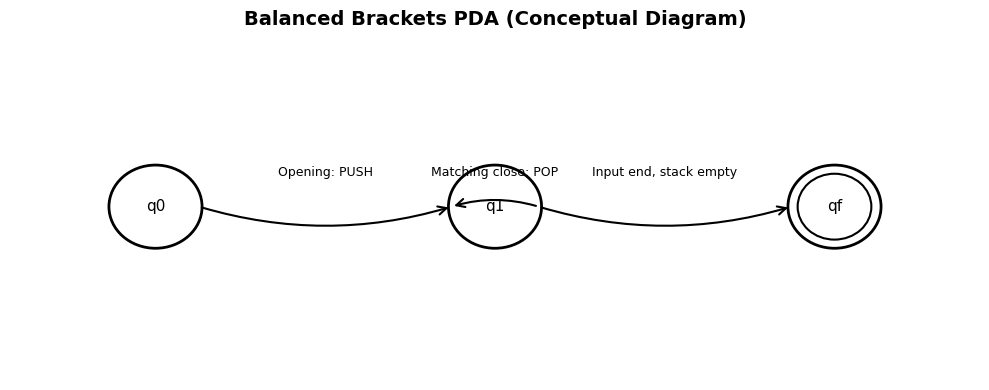

Saved: balanced_brackets_pda.png


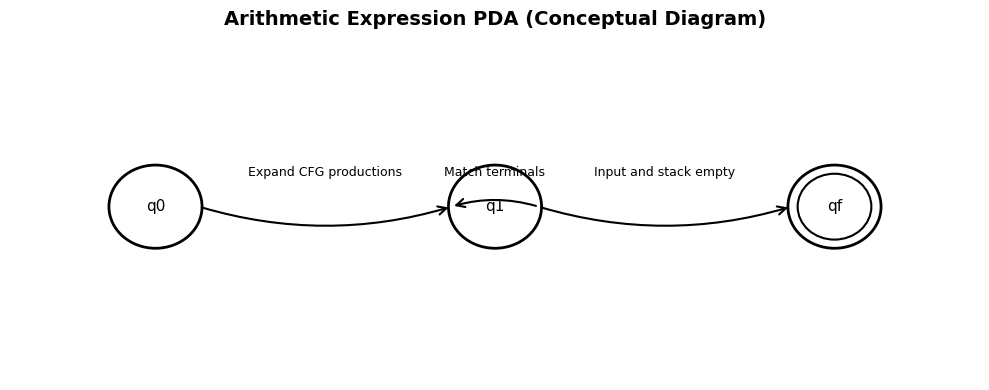

Saved: arithmetic_expression_pda.png


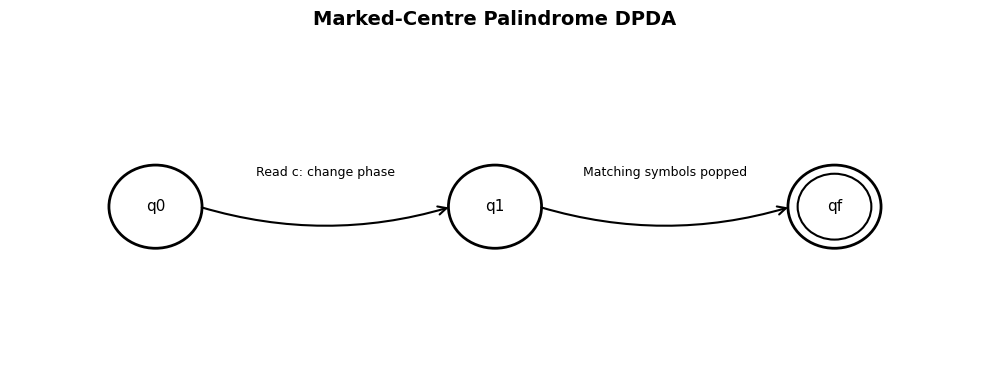

Saved: marked_palindrome_dpda.png


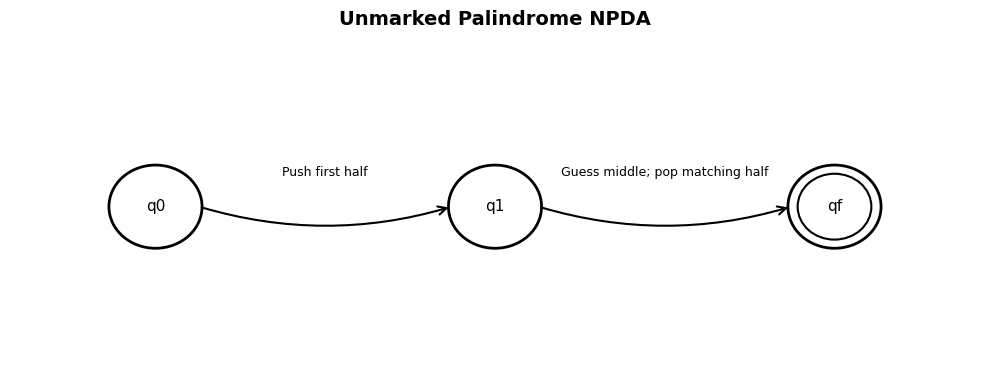

Saved: unmarked_palindrome_npda.png

FINAL COMPARISON

CASE STUDY 1: BALANCED PARENTHESES
Formal Model: CFG + DPDA
Technique: Push opening brackets and pop matching brackets.

CASE STUDY 2: ARITHMETIC EXPRESSIONS
Formal Model: CFG + CFG-to-NPDA
Technique: Grammar productions, parsing and operator precedence.

CASE STUDY 3: PALINDROMES
Formal Model: CFG + DPDA / NPDA
Technique: Stack matching and nondeterministic middle guessing.

PROJECT CONCLUSION

Pushdown Automata use a stack to recognize context-free languages.

The three case studies demonstrate how CFG and PDA can be applied
to balanced brackets, arithmetic expression validation and
palindrome checking.

CFG describes the language using production rules.
PDA recognizes the language using states and a stack.

Therefore, PDA and CFG are useful in syntax checking,
expression parsing and language processing.

TASK 3 EXECUTION COMPLETED


In [1]:

# ================================================================
# TASK 3: CASE STUDIES WITH PDA AND CFG
# PUSHDOWN AUTOMATA AND CONTEXT-FREE GRAMMAR
#
# Student: Dande Durga Prasad
# Register Number: RA2411026050066
# Course: 21CSC301T - Formal Language and Automata
# ================================================================

import re
from collections import deque
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

print("=" * 70)
print("TASK 3: CASE STUDIES WITH PDA AND CFG")
print("PUSHDOWN AUTOMATA AND CONTEXT-FREE GRAMMAR")
print("=" * 70)


# ================================================================
# COMMON FUNCTION: CFG TO NPDA SIMULATION
# ================================================================

def cfg_to_pda_accepts(tokens, grammar, start_symbol, max_configs=50000):
    """
    Simulates the standard CFG-to-NPDA construction.

    The stack is represented as a tuple.
    The last element is the top of the stack.
    """

    initial_stack = (start_symbol,)
    queue = deque([(0, initial_stack)])
    visited = set()

    while queue and len(visited) < max_configs:
        position, stack = queue.popleft()
        configuration = (position, stack)

        if configuration in visited:
            continue

        visited.add(configuration)

        # Accept when all input is consumed and stack is empty
        if position == len(tokens) and len(stack) == 0:
            return True

        # No symbol available on stack
        if len(stack) == 0:
            continue

        top = stack[-1]
        remaining_stack = stack[:-1]

        # If top is a non-terminal, expand its productions
        if top in grammar:
            for production in grammar[top]:
                new_stack = remaining_stack + tuple(reversed(production))
                queue.append((position, new_stack))

        # If top is a terminal, match it with input
        else:
            if position < len(tokens) and tokens[position] == top:
                queue.append((position + 1, remaining_stack))

    return False


def show_result(label, accepted):
    print(f"{label:<25} | {'ACCEPTED' if accepted else 'REJECTED'}")


# ================================================================
# CASE STUDY 1: BALANCED PARENTHESES
# ================================================================

print("\n" + "=" * 70)
print("CASE STUDY 1: BALANCED PARENTHESES")
print("=" * 70)

print("""
Problem:
Design a PDA to check whether parentheses, square brackets,
and curly brackets are balanced and properly nested.

CFG:

S -> B S | B
B -> ( S ) | () | [ S ] | [] | { S } | {}

PDA Working:
1. Push every opening bracket onto the stack.
2. Read a closing bracket.
3. Check whether it matches the top of the stack.
4. Pop the matching opening bracket.
5. Accept if the input ends and the stack is empty.
""")


def balanced_bracket_pda(text):
    stack = []
    matching = {')': '(', ']': '[', '}': '{'}

    for char in text:
        if char in "([{":
            stack.append(char)

        elif char in ")]}":
            if not stack or stack[-1] != matching[char]:
                return False
            stack.pop()

        else:
            return False

    return len(stack) == 0


bracket_grammar = {
    "S": [("B", "S"), ("B",)],
    "B": [
        ("(", "S", ")"),
        ("(", ")"),
        ("[", "S", "]"),
        ("[", "]"),
        ("{", "S", "}"),
        ("{", "}")
    ]
}

bracket_tests = [
    "()",
    "[]{}",
    "([]{})",
    "{[()]}",
    "((()))",
    "()[]{}([])",
    "(",
    ")(",
    "([)]",
    "(())",
    "{]}"
]

print("\n--- Balanced Parentheses Test Results ---")

for test in bracket_tests:
    result = balanced_bracket_pda(test)
    show_result(test, result)


print("\n--- Stack Operations for {[()]} ---")

example = "{[()]}"
stack = []
matching = {')': '(', ']': '[', '}': '{'}

for char in example:
    if char in "([{":
        stack.append(char)
        operation = "PUSH"

    else:
        if stack and stack[-1] == matching[char]:
            stack.pop()
            operation = "POP"
        else:
            operation = "INVALID"

    print(
        f"Read: {char} | Operation: {operation:<20} | Stack: {stack}"
    )


print("\n--- CFG to PDA Verification ---")

for test in ["()", "([]{})", "{[()]}", "([)]", "(", "()[]{}"]:
    accepted = cfg_to_pda_accepts(
        list(test), bracket_grammar, "S"
    )
    show_result(test, accepted)


print("\n--- Ambiguity Analysis ---")

print("""
Original grammar:

S -> SS | (S) | [S] | {S} | () | [] | {}

The production S -> SS allows different groupings.
For example, ()()() can have multiple parse trees.

Revised grammar:

S -> BS | B
B -> (S) | () | [S] | [] | {S} | {}

The revised grammar gives one grouping for each sequence.
""")


# ================================================================
# CASE STUDY 2: ARITHMETIC EXPRESSION VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("CASE STUDY 2: ARITHMETIC EXPRESSION VALIDATION")
print("=" * 70)

print("""
Problem:
Validate arithmetic expressions using CFG and PDA.

Ambiguous Grammar:

E -> E + E | E * E | (E) | id

Revised Grammar:

E  -> T E2
E2 -> + T E2 | epsilon
T  -> F T2
T2 -> * F T2 | epsilon
F  -> (E) | id

Multiplication has higher precedence than addition.
Parentheses can change the evaluation order.
""")


# Revised grammar in right-recursive form
arithmetic_grammar = {
    "E": [("T", "E2")],
    "E2": [("+", "T", "E2"), ()],
    "T": [("F", "T2")],
    "T2": [("*", "F", "T2"), ()],
    "F": [("(", "E", ")"), ("id",)]
}


def tokenize_expression(expression):
    """
    Converts an expression into tokens.
    Example: id+id*id -> ['id', '+', 'id', '*', 'id']
    """

    tokens = re.findall(r'id|[+*()]|\S', expression)
    return tokens


def validate_arithmetic(expression):
    tokens = tokenize_expression(expression)

    # Reject unknown characters
    if "".join(tokens) != re.sub(r"\s+", "", expression):
        return False

    return cfg_to_pda_accepts(
        tokens, arithmetic_grammar, "E"
    )


arithmetic_tests = [
    "id",
    "id+id",
    "id+id*id",
    "(id+id)*id",
    "id*(id+id)*id",
    "((id))",
    "id+id+id",
    "",
    "id+",
    "+id",
    "id id",
    "(id+id",
    "id+*id"
]

print("\n--- Arithmetic Expression Test Results ---")

for expression in arithmetic_tests:
    result = validate_arithmetic(expression)
    display = expression if expression else "EMPTY"
    show_result(display, result)


print("\n--- PDA Trace for id+id*id ---")

trace = [
    ("id + id * id", "E"),
    ("id + id * id", "T E2"),
    ("id + id * id", "F T2 E2"),
    ("id + id * id", "id T2 E2"),
    ("+ id * id", "T2 E2"),
    ("+ id * id", "E2"),
    ("+ id * id", "+ T E2"),
    ("id * id", "T E2"),
    ("id * id", "F T2 E2"),
    ("id * id", "id T2 E2"),
    ("* id", "T2 E2"),
    ("* id", "* F T2 E2"),
    ("id", "F T2 E2"),
    ("id", "id T2 E2"),
    ("EMPTY", "T2 E2"),
    ("EMPTY", "E2"),
    ("EMPTY", "EMPTY")
]

print("Result: ACCEPTED")
print("\nPDA Configuration Trace:")

for remaining, stack_top in trace:
    print(
        f"Remaining Input: {remaining:<20} | Stack Top: {stack_top}"
    )


print("\n--- CFG to PDA Verification ---")

for expression in [
    "id",
    "id+id",
    "id+id*id",
    "(id+id)*id",
    "id+",
    "+id"
]:
    result = validate_arithmetic(expression)
    show_result(expression if expression else "EMPTY", result)


print("\n--- Ambiguity Demonstration ---")

print("""
Expression: id+id*id
Assume id values are 2, 3 and 4.

Parse 1: id + (id * id)

2 + (3 * 4)
2 + 12
Result = 14

Parse 2: (id + id) * id

(2 + 3) * 4
5 * 4
Result = 20

The ambiguous grammar permits two interpretations.
The revised grammar gives multiplication higher precedence.
Therefore, id+id*id evaluates to 14.
""")


print("--- Leftmost Derivation ---")

derivation = [
    "E",
    "T E2",
    "F T2 E2",
    "id T2 E2",
    "id E2",
    "id + T E2",
    "id + F T2 E2",
    "id + id T2 E2",
    "id + id * F T2 E2",
    "id + id * id T2 E2",
    "id + id * id E2",
    "id + id * id"
]

for step in derivation:
    print(step)


# ================================================================
# CASE STUDY 3: PALINDROME CHECKING
# ================================================================

print("\n" + "=" * 70)
print("CASE STUDY 3: PALINDROME CHECKING")
print("=" * 70)

print("""
Problem:
A palindrome is a string that reads the same from left to right
and right to left.

Unmarked Palindrome CFG:

S -> aSa | bSb | a | b | epsilon

Marked-Centre CFG:

S -> aSa | bSb | c

The marked-centre PDA reads the first half and pushes symbols.
After reading c, it changes to the popping phase.

The unmarked palindrome NPDA guesses the middle using an
epsilon transition or consumes one middle symbol for odd length.
""")


# Unmarked palindrome grammar over {a, b}
palindrome_grammar = {
    "S": [
        ("a", "S", "a"),
        ("b", "S", "b"),
        ("a",),
        ("b",),
        ()
    ]
}


# Marked-centre grammar over {a, b, c}
marked_palindrome_grammar = {
    "S": [
        ("a", "S", "a"),
        ("b", "S", "b"),
        ("c",)
    ]
}


def unmarked_palindrome_npda(text):
    if any(char not in "ab" for char in text):
        return False

    return text == text[::-1]


def marked_centre_dpda(text):
    if "c" not in text:
        return False

    if text.count("c") != 1:
        return False

    centre = text.index("c")
    first_half = text[:centre]
    second_half = text[centre + 1:]

    if any(char not in "ab" for char in first_half + second_half):
        return False

    return first_half == second_half[::-1]


print("\n--- Marked-Centre Palindrome DPDA Tests ---")

marked_tests = [
    "c",
    "aca",
    "abcba",
    "abbcbba",
    "babcbab",
    "aabacabaa",
    "ab",
    "abcab",
    "abcb",
    "acca",
    "abcbaa"
]

for test in marked_tests:
    result = marked_centre_dpda(test)
    show_result(test, result)


print("\n--- Unmarked Palindrome NPDA Tests ---")

unmarked_tests = [
    "",
    "aa",
    "abba",
    "baab",
    "abbbba",
    "aabbaabbaa",
    "a",
    "b",
    "aba",
    "abc",
    "abab",
    "aabb",
    "abbaa"
]

for test in unmarked_tests:
    result = unmarked_palindrome_npda(test)
    display = test if test else "epsilon"
    show_result(display, result)


print("\n--- CFG to PDA Verification ---")

for test in ["", "a", "b", "aa", "abba", "baab", "aba", "ab"]:
    result = cfg_to_pda_accepts(
        list(test), palindrome_grammar, "S"
    )
    display = test if test else "epsilon"
    show_result(display, result)


print("\n--- Marked-Centre PDA Stack Trace: abcba ---")

text = "abcba"
stack = []

for char in text:
    if char in "ab" and "c" not in text[:text.index(char)]:
        # The first two symbols are pushed before the centre.
        pass

# Explicit trace for abcba
stack = []
for char in "ab":
    stack.append(char)
    print(
        f"Read: {char} | Operation: {'PUSH':<20} | Stack: {stack}"
    )

print(
    f"Read: c | Operation: {'CHANGE TO POP':<20} | Stack: {stack}"
)

for char in "ba":
    if stack and stack[-1] == char:
        stack.pop()
        operation = "POP"
    else:
        operation = "INVALID"

    print(
        f"Read: {char} | Operation: {operation:<20} | Stack: {stack}"
    )


print("\n--- Corrected Palindrome Derivations ---")

print("""
1. Unmarked palindrome: ababa

Grammar:
S -> aSa | bSb | a | b | epsilon

Derivation:
S => aSa
  => abSba
  => ababa

This grammar generates palindromes over {a, b}.


2. Marked-centre palindrome: abcba

Grammar:
S -> aSa | bSb | c

Derivation:
S => aSa
  => abSba
  => abcba

The symbol c is the marked centre.
The marked-centre grammar generates strings of the form w c w^R.
""")


print("\n--- Marked-Centre CFG to PDA Verification ---")

for test in ["c", "aca", "abcba", "abbcbba", "ab", "abcab"]:
    result = cfg_to_pda_accepts(
        list(test), marked_palindrome_grammar, "S"
    )
    show_result(test, result)


# ================================================================
# GENERATING PDA DIAGRAMS
# ================================================================

print("\n" + "=" * 70)
print("GENERATING PDA DIAGRAMS")
print("=" * 70)


def draw_diagram(filename, title, states, arrows):
    """
    Draws a simplified conceptual PDA state diagram.
    These diagrams illustrate the main states and transitions.
    """

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 4)
    ax.axis("off")

    positions = {}

    for name, x, y, final in states:
        positions[name] = (x, y)

        circle = Circle(
            (x, y),
            0.48,
            fill=False,
            linewidth=2
        )
        ax.add_patch(circle)

        if final:
            inner = Circle(
                (x, y),
                0.38,
                fill=False,
                linewidth=1.5
            )
            ax.add_patch(inner)

        ax.text(
            x, y, name,
            ha="center",
            va="center",
            fontsize=11
        )

    for source, target, label in arrows:
        x1, y1 = positions[source]
        x2, y2 = positions[target]

        arrow = FancyArrowPatch(
            (x1 + 0.45, y1),
            (x2 - 0.45, y2),
            arrowstyle="->",
            mutation_scale=15,
            linewidth=1.5,
            connectionstyle="arc3,rad=0.15"
        )

        ax.add_patch(arrow)

        ax.text(
            (x1 + x2) / 2,
            (y1 + y2) / 2 + 0.35,
            label,
            ha="center",
            fontsize=9
        )

    ax.set_title(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", filename)


# Diagram 1: Balanced brackets
draw_diagram(
    "balanced_brackets_pda.png",
    "Balanced Brackets PDA (Conceptual Diagram)",
    [
        ("q0", 1.5, 2, False),
        ("q1", 5, 2, False),
        ("qf", 8.5, 2, True)
    ],
    [
        ("q0", "q1", "Opening: PUSH"),
        ("q1", "q1", "Matching close: POP"),
        ("q1", "qf", "Input end, stack empty")
    ]
)


# Diagram 2: Arithmetic expression PDA
draw_diagram(
    "arithmetic_expression_pda.png",
    "Arithmetic Expression PDA (Conceptual Diagram)",
    [
        ("q0", 1.5, 2, False),
        ("q1", 5, 2, False),
        ("qf", 8.5, 2, True)
    ],
    [
        ("q0", "q1", "Expand CFG productions"),
        ("q1", "q1", "Match terminals"),
        ("q1", "qf", "Input and stack empty")
    ]
)


# Diagram 3: Marked-centre palindrome DPDA
draw_diagram(
    "marked_palindrome_dpda.png",
    "Marked-Centre Palindrome DPDA",
    [
        ("q0", 1.5, 2, False),
        ("q1", 5, 2, False),
        ("qf", 8.5, 2, True)
    ],
    [
        ("q0", "q1", "Read c: change phase"),
        ("q1", "qf", "Matching symbols popped")
    ]
)


# Diagram 4: Unmarked palindrome NPDA
draw_diagram(
    "unmarked_palindrome_npda.png",
    "Unmarked Palindrome NPDA",
    [
        ("q0", 1.5, 2, False),
        ("q1", 5, 2, False),
        ("qf", 8.5, 2, True)
    ],
    [
        ("q0", "q1", "Push first half"),
        ("q1", "qf", "Guess middle; pop matching half")
    ]
)


# ================================================================
# FINAL COMPARISON
# ================================================================

print("\n" + "=" * 70)
print("FINAL COMPARISON")
print("=" * 70)

print("""
CASE STUDY 1: BALANCED PARENTHESES
Formal Model: CFG + DPDA
Technique: Push opening brackets and pop matching brackets.

CASE STUDY 2: ARITHMETIC EXPRESSIONS
Formal Model: CFG + CFG-to-NPDA
Technique: Grammar productions, parsing and operator precedence.

CASE STUDY 3: PALINDROMES
Formal Model: CFG + DPDA / NPDA
Technique: Stack matching and nondeterministic middle guessing.
""")


print("=" * 70)
print("PROJECT CONCLUSION")
print("=" * 70)

print("""
Pushdown Automata use a stack to recognize context-free languages.

The three case studies demonstrate how CFG and PDA can be applied
to balanced brackets, arithmetic expression validation and
palindrome checking.

CFG describes the language using production rules.
PDA recognizes the language using states and a stack.

Therefore, PDA and CFG are useful in syntax checking,
expression parsing and language processing.
""")

print("=" * 70)
print("TASK 3 EXECUTION COMPLETED")
print("=" * 70)
